# The efficiency-uniformity continuation: the curve it traces, and where published iterates dominate it

**Question:** What curve does a continuation on one loss trace between diffraction efficiency and uniformity on the 10 x 10 trap task, is that curve the Pareto front of the task, and where do iterates of published methods dominate it?

- Level: 4, proposed methods (the efficiency-uniformity continuation).
- Prerequisites: `05-optimization/01-the-cost-and-its-gradient`, and `03-gerchberg-saxton/02-weights-for-uniformity` for the loops that give the single points.
- Reading time: about 30 minutes. The notebook runs in a few minutes.

## Objectives

Every method in the literature reports its quality as one pair of numbers, an efficiency and a uniformity, and the choice between methods is usually a choice between pairs. But a pair is one point of a curve: change the weight of a cost, the number of iterations or the efficiency target and the same method lands somewhere else. This notebook asks what the curve is. By the end you can:

- place any hologram of a trap array in the plane of efficiency and uniformity, and say what dominating another one means;
- state the loss that the efficiency-uniformity continuation minimises, and say what its two terms and its parameter $\lambda$ do;
- run the single-point methods of the product and the continuation that traces the curve, and read both on one figure;
- decide from the numbers whether a method sits on the curve, and by how much it falls short;
- stress the claim with a stronger baseline than the benchmark's, and say what survives and why the curve is not the Pareto front;
- measure how much area the curve adds over the published points, and how that depends on the reference point of the hypervolume.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m04_gs, m05_gaa, m06_gsw, m07_phase_fixed_wgs
from pipeline.model.holo.methods.beyond import b5_pareto
from pipeline.model.holo.methods.beyond.b5_pareto import hypervolume, pareto_indices
from pipeline.model.holo.methods.optim import m09_direct_search, m11_wirtinger_adam

from pipeline.model.holo.core import traps as T
from pipeline.model.holo.core.types import Target
print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook reads case C12 of `data/examples/cases.json`, the calibration task used throughout the optimisation topic.

- Owner: this repository; the case is synthetic and follows the 10 x 10 task of Di Leonardo, Ianni and Ruocco (2007).
- Licence class: generated data under the repository's own licence, no third-party dataset.
- File: `data/examples/cases.json`, case C12.

In [2]:
# case C12: the optical setup and the 100 traps of the 10 x 10 task
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C12"]
setup = build.setup_of(rec)
target = build.target_of(rec)
print(rec["case_id"], "|", len(target.traps), "traps | SLM", setup.n_pix, "x", setup.n_pix, "pixels")

C12_calibration | 100 traps | SLM 256 x 256 pixels


## Method

### The plane and the loss

With $I_m$ the fraction of the input power that reaches trap $m$, the efficiency is $e = \sum_m I_m$ and the uniformity is $u = 1 - (\max I - \min I) / (\max I + \min I)$ of the intensities divided by their target weights (Di Leonardo et al., 2007). A larger $e$ and a larger $u$ are both better, so hologram A dominates hologram B when it is at least as good in both and strictly better in one. The set of holograms that nothing dominates is the Pareto front (Boyd and Vandenberghe, 2004, section 4.7). A method with a free parameter, such as the weight $f$ of the cost of Polin et al. (2005) or the number of iterations, traces a curve in this plane; a method without one gives a point.

The efficiency-uniformity continuation traces its curve by a continuation on one loss. The curve is the output of a method and not, by itself, a Pareto front: only a set computed from measured points, none of which any measured point dominates, is one, and the sections below show points of the curve that iterates of published methods dominate. Writing $T_m = e_0 w_m / \sum_k w_k$ for the equal-trap target at the efficiency $e_0$ of a starting hologram,

$$L_\lambda(\phi) = (1 - \lambda)\,\frac{\sum_m (I_m - T_m)^2}{\sum_m T_m^2} \;-\; \lambda\,\frac{\sum_m I_m}{e_0}, \qquad \lambda \in [0, 1].$$

At $\lambda = 0$ the loss asks for equal traps at the efficiency $e_0$ and nothing more. At $\lambda = 1$ it asks for light only, and equality is not asked for at all. In between it trades one against the other. The efficiency-uniformity continuation solves the loss for a grid of $\lambda$ from 0 to 1, each time warm-started from the previous solution, with conjugate gradient, and keeps the non-dominated results. Dividing the two terms by $\sum T^2$ and by $e_0$ makes both dimensionless and of order one; that scaling is the pipeline's reading of the research dossier, which does not state one. The hypervolume is the area of the plane, measured from the origin, that the points dominate: a curve that dominates more has a larger hypervolume.

The first cell runs only the two ends, $\lambda = 0$ and $\lambda = 1$, with 15 conjugate-gradient iterations each, to show what each term asks for before the whole curve is traced.

In [3]:
# the two ends of the loss: lambda = 0 asks for equal traps, lambda = 1 asks for light only
ends = b5_pareto.run(setup, target, budget=Budget(15), rng=Rng(1), n_lambda=2)
for lam, (eff, uni, sig) in zip(ends.meta["lambdas"], ends.meta["front"]):
    print(f"lambda {lam:.0f}: efficiency {eff:.4f}  uniformity {uni:.4f}  "
          f"rel. std {sig:.2f} %")
    print(f"             dimmest trap over the brightest: {uni / (2 - uni):.4f}")
print(f"efficiency of the start (phase-fixed WGS): {ends.meta['e0']:.4f}")

lambda 0: efficiency 0.7930  uniformity 1.0000  rel. std 0.00 %
             dimmest trap over the brightest: 1.0000
lambda 1: efficiency 0.8293  uniformity 0.0062  rel. std 82.10 %
             dimmest trap over the brightest: 0.0031
efficiency of the start (phase-fixed WGS): 0.7930


The two ends behave as the loss says. At $\lambda = 0$ the array is perfectly equal, with a relative standard deviation of 0.00 percent and a uniformity of 1.0000, at an efficiency of 0.7930, which is exactly the $e_0$ of the start. At $\lambda = 1$ the optimiser has lifted the efficiency to 0.8293 and given up on equality: the relative standard deviation is 82.10 percent and the uniformity is 0.0062, so the dimmest trap is nearly dark: with the uniformity of the Method section, 0.0062 means that the dimmest trap holds 0.0031 of the intensity of the brightest (printed above), and the relative standard deviation of 82.10 percent says that the spread is not the work of one trap alone. The two ends are far apart in uniformity, from 1.0000 to 0.0062, and close in efficiency, 0.7930 to 0.8293, a gain of 4.6 percent of the light. This is the first fact about the curve, and the cells below measure it with the whole curve: the trade-off on this task is steep, and almost all of it is paid in uniformity.

## Comparison

The single-point methods are what the efficiency-uniformity continuation is measured against. Each runs here as the pipeline's own implementation, with the benchmark's budget of 30 iterations and the same seed: plain Gerchberg-Saxton, the generalized adaptive additive loop and the weighted loop of Di Leonardo et al. (2007), and phase-fixed weighted GS, the large-array method of Kim et al. (2019). The first cell runs those four.

In [4]:
# four projection methods at the benchmark budget of 30 iterations, seed 1
h04 = m04_gs.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
h05 = m05_gaa.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
h06 = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
h07 = m07_phase_fixed_wgs.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
for name, h in (("Gerchberg-Saxton", h04), ("Generalized adaptive additive GS", h05), ("Weighted GS", h06),
    ("Phase-fixed weighted GS", h07)):
    print(f"{name:32s} efficiency {h['efficiency']:.4f}  uniformity {h['uniformity']:.4f}")

Gerchberg-Saxton                 efficiency 0.8105  uniformity 0.6172
Generalized adaptive additive GS efficiency 0.8089  uniformity 0.7053
Weighted GS                      efficiency 0.8023  uniformity 0.9665
Phase-fixed weighted GS          efficiency 0.7930  uniformity 0.9997


Two more points come from the optimisation family. Direct search changes one pixel at a time to lower the cost of Polin et al. (2005), $C = -\langle I \rangle + f \sigma$, with $f = 0.5$; it pays an efficiency price for uniformity by construction. Wirtinger-Adam, from the previous notebook, minimises the quadratic loss by gradient steps.

In [5]:
# direct search (2 sweeps over the pixels) and Wirtinger-Adam (30 iterations), same task and seed
h09 = m09_direct_search.run(setup, target, budget=Budget(2), rng=Rng(1)).history[-1]
h11 = m11_wirtinger_adam.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
for name, h in (("Direct search", h09), ("Wirtinger gradient with Adam", h11)):
    print(f"{name:32s} efficiency {h['efficiency']:.4f}  uniformity {h['uniformity']:.4f}")

Direct search                    efficiency 0.6584  uniformity 0.9994
Wirtinger gradient with Adam     efficiency 0.7629  uniformity 0.9327


The figure places the six results in the plane of efficiency and uniformity.

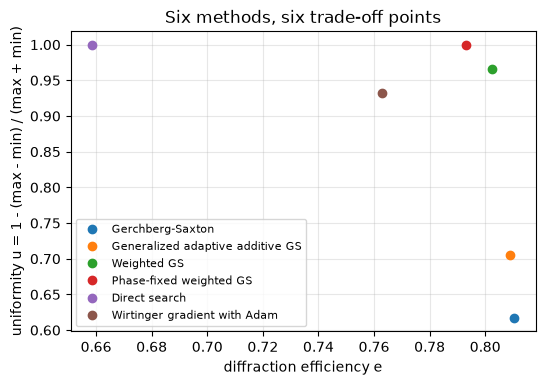

In [6]:
# the six single-point results in the plane of efficiency and uniformity
base = {"Gerchberg-Saxton": h04, "Generalized adaptive additive GS": h05, "Weighted GS": h06,
    "Phase-fixed weighted GS": h07, "Direct search": h09, "Wirtinger gradient with Adam": h11}
fig, ax = plt.subplots(figsize=(6.0, 3.9))
for name, h in base.items():
    ax.plot(h["efficiency"], h["uniformity"], "o", label=name)
ax.set_xlabel("diffraction efficiency e")
ax.set_ylabel("uniformity u = 1 - (max - min) / (max + min)")
ax.set_title("Six methods, six trade-off points")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()

The six points fall into three groups. Gerchberg-Saxton and generalized adaptive additive GS have the highest efficiency, 0.8105 and 0.8089, and the lowest uniformity, 0.6172 and 0.7053: they are the projection loops that put light in the traps and leave the traps unequal. Weighted GS has an efficiency of 0.8023 and a uniformity of 0.9665, and phase-fixed weighted GS sits at 0.7930 and 0.9997 after the same 30 iterations; Wirtinger gradient with Adam is near them at 0.7629 and 0.9327. Direct search is at the uniform end too, with a uniformity of 0.9994 and an efficiency of only 0.6584, which is the price of its weight $f = 0.5$. The figure shows six points, and nothing in it says whether a point could be moved up or to the right with the same method. It cannot show the curve that each parameter would trace, and that is the gap the efficiency-uniformity continuation addresses: the literature compares these points, none of the sources cited here reports the whole curve on one task, and this notebook did not search for one that does.

### Direct search, the one point that is not a projection loop

Direct search (Polin et al. 2005) does not carry light back and forth: it changes one pixel at a time. With $I_m$ the trap intensities and $I^D_m = w_m/\bar w$ the design intensities, it lowers the cost

$$C=-\langle I\rangle+f\,\sigma,\qquad \sigma=\sqrt{\frac1M\sum_m\big(I_m-\gamma I^D_m\big)^2},\qquad \gamma=\frac{\sum_m I_m I^D_m}{\sum_m \big(I^D_m\big)^2},$$

where $\langle I\rangle$ is the mean trap intensity (the efficiency divided by the $M$ traps), $\sigma$ the spread of the traps around the best-fitting multiple $\gamma I^D$ of the design, and $f$ the weight of uniformity against light. A sweep visits the $N^2$ pixels once in a random order; at each pixel it tries $P = 8$ phases $2\pi k/P$ and keeps the best one only if it lowers $C$, so $C$ never rises. Changing pixel $j$ from the phase $\phi$ to $\phi'$ changes every trap field by $V_m \leftarrow V_m + (A_j/N^2)\,(e^{i\phi'} - e^{i\phi})\,e^{-i\Delta_j^m}$, with $A_j$ the beam amplitude at the pixel and $e^{-i\Delta_j^m}$ the propagation factor from the pixel to trap $m$: an update of order $M$ and not a new transform, which is what makes the $P N^2$ trials of a sweep affordable. Three limits follow from the construction: the visits are sequential, a pixel-by-pixel descent cannot leave a local minimum, and a sweep costs $P N^2$ trials of order $M$ however good the hologram already is. The cell runs direct search for two sweeps at $f = 0$, $0.5$ and $2$ and prints the efficiency and the uniformity after each sweep, the trials so far, and the number of pixels changed.

In [7]:
# direct search: the cost of Polin et al. at three weights f, two sweeps each, the state after every sweep
direct = {}
for f in (0.0, 0.5, 2.0):
    direct[f] = m09_direct_search.run(setup, target, budget=Budget(2), rng=Rng(1), f=f)
    for h in direct[f].history:
        print(f"f = {f:.1f}, sweep {h['iteration']}: efficiency {h['efficiency']:.4f}  "
              f"uniformity {h['uniformity']:.4f}  trials so far {h['trials']}")
    changed, visits = direct[f].meta["accepted"], 2 * setup.n_pix**2
    print(f"           pixels changed over the two sweeps: {changed} of {visits} visits")


f = 0.0, sweep 1: efficiency 0.7584  uniformity 0.0086  trials so far 524288
f = 0.0, sweep 2: efficiency 0.7727  uniformity 0.0011  trials so far 1048576
           pixels changed over the two sweeps: 19635 of 131072 visits
f = 0.5, sweep 1: efficiency 0.6582  uniformity 0.9996  trials so far 524288
f = 0.5, sweep 2: efficiency 0.6584  uniformity 0.9994  trials so far 1048576
           pixels changed over the two sweeps: 17036 of 131072 visits
f = 2.0, sweep 1: efficiency 0.5366  uniformity 0.9997  trials so far 524288
f = 2.0, sweep 2: efficiency 0.5366  uniformity 0.9996  trials so far 1048576
           pixels changed over the two sweeps: 10130 of 131072 visits


The figure puts the three weights in the plane of efficiency and uniformity, next to the weighted loop and phase-fixed weighted GS.

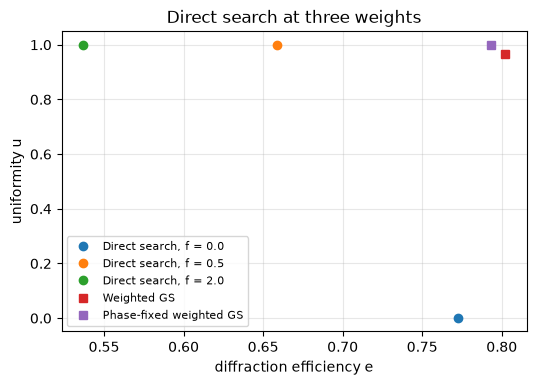

In [8]:
# the three direct-search weights after two sweeps, with weighted GS and phase-fixed weighted GS of the six-point figure
fig, ax = plt.subplots(figsize=(6.0, 3.9))
for f, res in direct.items():
    ax.plot(res.history[-1]["efficiency"], res.history[-1]["uniformity"], "o", label=f"Direct search, f = {f}")
for name in ("Weighted GS", "Phase-fixed weighted GS"):
    ax.plot(base[name]["efficiency"], base[name]["uniformity"], "s", label=name)
ax.set_xlabel("diffraction efficiency e")
ax.set_ylabel("uniformity u")
ax.set_title("Direct search at three weights")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()


The weight $f$ sets where direct search lands, and a second sweep adds almost nothing. At $f = 0$ the cost asks for light only: the efficiency reaches 0.7727 and the uniformity collapses to 0.0011. At $f = 0.5$, the weight of the six-point figure, one sweep gives an efficiency of 0.6582 and a uniformity of 0.9996 and the second sweep moves them to 0.6584 and 0.9994; at $f = 2$ the efficiency is 0.5366 after both sweeps. Each sweep is 524288 trials, 8 phases at each of the 65536 pixels, and the pixels changed over the two sweeps are 19635, 17036 and 10130 of 131072 visits, so most visits change nothing. At $f = 0.5$ and $2$ this is the construction showing its limit: after one sweep a pixel-by-pixel descent has no move left that lowers the cost, and the trade-off it settles on, 0.6584 of the light against 0.7930 for phase-fixed weighted GS at a uniformity of about 1, is set by the weight and not found by the search. The figure puts the three weights against weighted GS and phase-fixed weighted GS: direct search at $f = 0.5$ and $2$ sits at the uniform end with less light than phase-fixed weighted GS, and at $f = 0$ it sits at the other end with more light than phase-fixed weighted GS and almost no uniformity. It does not say that another start or another order of the visits would not do better; the notebook ran one start, the superposition of the case, and one random order per weight.

## Evidence

### The curve by continuation on one loss

The claim of the efficiency-uniformity continuation is that a continuation on one loss returns the whole curve at the price of a few conjugate-gradient runs, and that no single-point method sits on it. The next cell runs it with 20 values of $\lambda$ and 15 conjugate-gradient iterations for each, each with its line search, after a 30-iteration phase-fixed weighted GS start, and prints seven of the 20 points; every single-point method below gets 30 iterations, so the curve costs far more than any one of them.

In [9]:
# the curve: 20 values of lambda, 15 conjugate-gradient iterations each, each warm-started from its neighbour
res_b5 = b5_pareto.run(setup, target, budget=Budget(15), rng=Rng(1))
front = res_b5.meta["front"]
for k in (0, 3, 6, 9, 12, 15, 19):
    print(f"lambda {res_b5.meta['lambdas'][k]:.2f}: efficiency {front[k, 0]:.4f}  "
          f"uniformity {front[k, 1]:.4f}  rel. std {front[k, 2]:.2f} %")
print(f"points kept as non-dominated: {len(res_b5.meta['pareto'])} of {len(front)}")

lambda 0.00: efficiency 0.7930  uniformity 1.0000  rel. std 0.00 %
lambda 0.16: efficiency 0.8034  uniformity 0.9769  rel. std 1.02 %
lambda 0.32: efficiency 0.8087  uniformity 0.9425  rel. std 2.23 %
lambda 0.47: efficiency 0.8119  uniformity 0.9077  rel. std 3.99 %
lambda 0.63: efficiency 0.8146  uniformity 0.8449  rel. std 6.99 %
lambda 0.79: efficiency 0.8183  uniformity 0.7083  rel. std 12.75 %
lambda 1.00: efficiency 0.8334  uniformity 0.0074  rel. std 72.89 %
points kept as non-dominated: 20 of 20


The curve is not a cloud: all 20 points are non-dominated among themselves. Its efficiency runs from 0.7930 to 0.8334 while its uniformity runs from 1.0000 to 0.0074, and most of the loss of uniformity comes at the end of the curve, between $\lambda = 0.79$ and $\lambda = 1$. Now the claim: for each single point, the cell counts the curve points that dominate it, and reads the efficiency the curve offers at the same uniformity. The cell also compares the hypervolume of the curve with that of the single points, which is the acceptance criterion of the efficiency-uniformity continuation in the method ladder.

In [10]:
# for every single point: the curve points that dominate it, and the curve efficiency at its uniformity
by_uniformity = np.argsort(front[:, 1])
for name, h in base.items():
    e, u = h["efficiency"], h["uniformity"]
    better = (front[:, 0] >= e) & (front[:, 1] >= u) & ((front[:, 0] > e) | (front[:, 1] > u))
    offered = np.interp(u, front[by_uniformity, 1], front[by_uniformity, 0])
    print(f"{name:32s} dominated by {int(better.sum()):2d} curve points | "
          f"curve efficiency at its uniformity {offered:.4f} "
          f"against {e:.4f}")
pairs = {k: [h["efficiency"], h["uniformity"]] for k, h in base.items()}
hv_six = hypervolume(np.array(list(pairs.values())))
hv_four = hypervolume(np.array([pairs[k] for k in ("Gerchberg-Saxton", "Generalized adaptive additive GS",
    "Direct search", "Weighted GS")]))
print(f"hypervolume of the curve: {res_b5.meta['hypervolume']:.4f}")
print(f"hypervolume of the six points: {hv_six:.4f} | of the four of the criterion: {hv_four:.4f}")

Gerchberg-Saxton                 dominated by  9 curve points | curve efficiency at its uniformity 0.8205 against 0.8105
Generalized adaptive additive GS dominated by  9 curve points | curve efficiency at its uniformity 0.8184 against 0.8089
Weighted GS                      dominated by  2 curve points | curve efficiency at its uniformity 0.8056 against 0.8023
Phase-fixed weighted GS          dominated by  0 curve points | curve efficiency at its uniformity 0.7931 against 0.7930
Direct search                    dominated by  1 curve points | curve efficiency at its uniformity 0.7932 against 0.6584
Wirtinger gradient with Adam     dominated by  7 curve points | curve efficiency at its uniformity 0.8097 against 0.7629
hypervolume of the curve: 0.8198
hypervolume of the six points: 0.8074 | of the four of the criterion: 0.8028


The figure draws the curve and the six single points together.

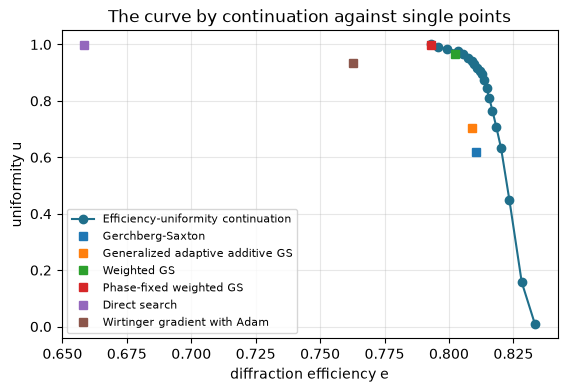

In [11]:
# the curve and the six single points in one plane
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot(front[:, 0], front[:, 1], "o-", color="#1f6f8b", label="Efficiency-uniformity continuation")
for name, h in base.items():
    ax.plot(h["efficiency"], h["uniformity"], "s", label=name)
ax.set_xlabel("diffraction efficiency e")
ax.set_ylabel("uniformity u")
ax.set_title("The curve by continuation against single points")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()

Five of the six single points are dominated, by between 1 and 9 points of the curve; phase-fixed weighted GS is not, and the reason is the start: the continuation begins from phase-fixed weighted GS's own hologram, so the uniform end of the curve is phase-fixed weighted GS refined, and at phase-fixed weighted GS's uniformity the curve offers 0.7931 against 0.7930, a difference below the fourth digit. The other margins differ a great deal. At the uniformity of direct search the curve offers an efficiency of 0.7932 against 0.6584, a gain of 0.1348 of the light; for Wirtinger gradient with Adam it offers 0.8097 against 0.7629. For the projection loops Gerchberg-Saxton and generalized adaptive additive GS the margin is about 0.01, and for weighted GS it is 0.8056 against 0.8023. The hypervolume of the curve is 0.8198 against 0.8074 for the six points and 0.8028 for the four of the criterion, so the acceptance criterion of the efficiency-uniformity continuation holds. What the figure does not say is how robust these margins are: they come from one seed and one budget. The hypervolume is also a blunt tool here, because the origin is far and every point already covers about 0.8 of the unit square.

The curve above comes from one seed. The next cell repeats the whole test on seeds 2 and 3: the six single points, the 20-point curve from a 30-iteration start, the number of single points below the curve and the hypervolumes of the criterion.

In [12]:
# the curve test on two more seeds: the six single points, the 20-point curve, the dominated points, the hypervolumes
runners = {"Gerchberg-Saxton": (m04_gs.run, 30), "Generalized adaptive additive GS": (m05_gaa.run, 30),
    "Weighted GS": (m06_gsw.run, 30),
           "Phase-fixed weighted GS": (m07_phase_fixed_wgs.run, 30), "Direct search": (m09_direct_search.run, 2),
           "Wirtinger gradient with Adam": (m11_wirtinger_adam.run, 30)}
for seed in (2, 3):
    points = {name: run(setup, target, budget=Budget(b), rng=Rng(seed)).history[-1]
              for name, (run, b) in runners.items()}
    seeded = b5_pareto.run(setup, target, budget=Budget(15), rng=Rng(seed))
    fr = seeded.meta["front"]
    below = []
    for name, h in points.items():
        e, u = h["efficiency"], h["uniformity"]
        if np.any((fr[:, 0] >= e) & (fr[:, 1] >= u) & ((fr[:, 0] > e) | (fr[:, 1] > u))):
            below.append(name)
    xy = {name: [h["efficiency"], h["uniformity"]] for name, h in points.items()}
    hv_four = hypervolume(np.array([xy[k] for k in ("Gerchberg-Saxton", "Generalized adaptive additive GS",
        "Direct search", "Weighted GS")]))
    print(f"seed {seed}: curve efficiency {fr[0, 0]:.4f} to {fr[-1, 0]:.4f}, "
          f"uniformity {fr[0, 1]:.4f} to {fr[-1, 1]:.4f}")
    print(f"   single points below the curve: {len(below)} of 6 ({', '.join(below)})")
    hv_six = hypervolume(np.array(list(xy.values())))
    print(f"   hypervolume: curve {seeded.meta['hypervolume']:.4f}, six points {hv_six:.4f}, "
          f"the four of the criterion {hv_four:.4f}")


seed 2: curve efficiency 0.7908 to 0.8352, uniformity 1.0000 to 0.0150
   single points below the curve: 4 of 6 (Gerchberg-Saxton, Phase-fixed weighted GS, Direct search, Wirtinger gradient with Adam)
   hypervolume: curve 0.8218, six points 0.8113, the four of the criterion 0.8113
seed 3: curve efficiency 0.7931 to 0.8356, uniformity 1.0000 to 0.0053
   single points below the curve: 6 of 6 (Gerchberg-Saxton, Generalized adaptive additive GS, Weighted GS, Phase-fixed weighted GS, Direct search, Wirtinger gradient with Adam)
   hypervolume: curve 0.8216, six points 0.8115, the four of the criterion 0.8075


On seed 2 four of the six single points lie below the curve (generalized adaptive additive GS and weighted GS do not) and on seed 3 all six do, against five of six on seed 1: the count is not a constant of the task, and which of the loops sit on the curve changes with the seed. The hypervolume criterion holds on all three seeds: the curve has 0.8198, 0.8218 and 0.8216 (seeds 1, 2 and 3) against 0.8074, 0.8113 and 0.8115 for the six points and 0.8028, 0.8113 and 0.8075 for the four of the criterion. The curve covers an efficiency range of 0.7908 to 0.8352 on seed 2 and 0.7931 to 0.8356 on seed 3, close to the 0.7930 to 0.8334 of seed 1, and its uniformity ends at 0.0150 and 0.0053 against 0.0074. Three seeds are still few: they show how much the count moves and are not an interval for it.

### Where the curve fails: a stronger baseline than the benchmark's

The benchmark fixes 30 iterations for every method, and the curve above was started from a 30-iteration hologram. A fair test of a claim about a curve should give the baseline more effort, since a single-point method is only one run. The strongest baseline for the uniform end is the weighted loop, whose uniformity keeps improving with iterations. The cell runs it for 100 iterations and counts the points of the curve that it dominates.

In [13]:
# the strongest single-point baseline: weighted GS with 100 iterations instead of 30
res_long = m06_gsw.run(setup, target, budget=Budget(100), rng=Rng(1))
e_long, u_long = res_long.history[-1]["efficiency"], res_long.history[-1]["uniformity"]
beaten = (e_long >= front[:, 0]) & (u_long >= front[:, 1]) & ((e_long > front[:, 0]) | (u_long > front[:, 1]))
print(f"Weighted GS, 100 iterations: efficiency {e_long:.4f}  uniformity {u_long:.4f}")
print(f"curve points dominated by it: {int(beaten.sum())} of {len(front)}")
published = np.vstack([[[h["efficiency"], h["uniformity"]] for h in base.values()], [[e_long, u_long]]])
below_any = [bool(np.any(np.all(published >= p, axis=1) & np.any(published > p, axis=1))) for p in front[:, :2]]
print(f"curve points dominated by at least one of the seven published points: {sum(below_any)} of {len(front)}")

Weighted GS, 100 iterations: efficiency 0.8075  uniformity 0.9887
curve points dominated by it: 4 of 20
curve points dominated by at least one of the seven published points: 4 of 20


The claim fails in part. A weighted-GS hologram of 100 iterations, at an efficiency of 0.8075 and a uniformity of 0.9887, dominates 4 of the 20 points of the curve: the curve underestimates what is reachable near the uniform end, because its continuation began from a 30-iteration start with an efficiency of only 0.7930 and spent 15 iterations per value. The curve is not a property of the task alone but of the task, the starting hologram and the budget. The efficiency-uniformity continuation accepts a starting phase, so the repair is to begin the continuation from the better hologram. The cell does that with 8 values of $\lambda$ and 30 iterations each, and prints the two ends of the new curve.

In [14]:
# the same continuation started from that better hologram: 8 values of lambda, 30 iterations each
res_warm = b5_pareto.run(setup, target, budget=Budget(30), rng=Rng(1), n_lambda=8, init=res_long.phi)
front_warm = res_warm.meta["front"]
print(f"uniform end of the new curve: e {front_warm[0, 0]:.4f}  u {front_warm[0, 1]:.4f}")
print(f"efficiency end: e {front_warm[-1, 0]:.4f}  u {front_warm[-1, 1]:.4f}")
print(f"hypervolume, new curve: {res_warm.meta['hypervolume']:.4f} | "
      f"first curve: {res_b5.meta['hypervolume']:.4f}")

uniform end of the new curve: e 0.8075  u 1.0000
efficiency end: e 0.8370  u 0.0101
hypervolume, new curve: 0.8216 | first curve: 0.8198


The figure draws both curves and the 100-iteration point.

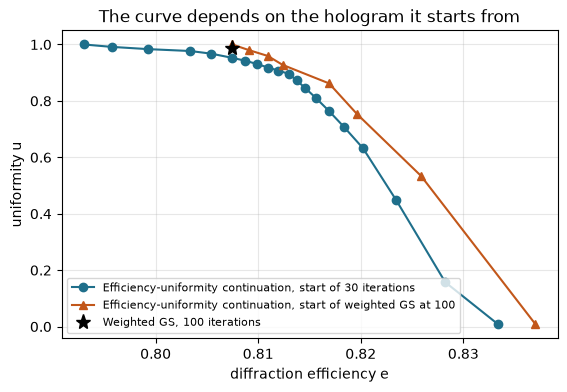

In [15]:
# both curves and the long weighted-GS point
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot(front[:, 0], front[:, 1], "o-", color="#1f6f8b",
    label="Efficiency-uniformity continuation, start of 30 iterations")
ax.plot(front_warm[:, 0], front_warm[:, 1], "^-", color="#c2571a",
    label="Efficiency-uniformity continuation, start of weighted GS at 100")
ax.plot(e_long, u_long, "k*", markersize=11, label="Weighted GS, 100 iterations")
ax.set_xlabel("diffraction efficiency e")
ax.set_ylabel("uniformity u")
ax.set_title("The curve depends on the hologram it starts from")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()

The new curve starts where the stronger baseline ends: its uniform end is at an efficiency of 0.8075 and a uniformity of 1.0000, which matches the efficiency of weighted GS at 100 iterations to four digits and removes the remaining 0.0113 of non-uniformity, and its efficiency end reaches 0.8370 against 0.8334 for the first curve. Its hypervolume, 0.8216, is above the 0.8198 of the first curve. The next cell asks how the two curves sit against each other.

In [16]:
# where the 8-point curve leaves the 20-point one uncovered, and the hypervolume of the two curves together
# dominance on efficiency and uniformity only: the relative std of the third column is better when lower
covered = [bool(np.any(np.all(front_warm[:, :2] >= p, axis=1) & np.any(front_warm[:, :2] > p, axis=1)))
           for p in front[:, :2]]
open_points = front[~np.array(covered)]
print(f"points of the first curve dominated by no point of the new one: {len(open_points)} of {len(front)}")
print(f"their efficiencies: {open_points[:, 0].min():.4f} to {open_points[:, 0].max():.4f}")
union = np.vstack([front, front_warm])[:, :2]
print(f"hypervolume of the union of both curves: {hypervolume(union[pareto_indices(union)]):.4f}")


points of the first curve dominated by no point of the new one: 5 of 20
their efficiencies: 0.7930 to 0.8282
hypervolume of the union of both curves: 0.8220


The two curves interleave: the new curve dominates 15 of the 20 points of the first, and 5, at efficiencies from 0.7930 to 0.8282, are dominated by no point of the new one, because its 8 values of $\lambda$ leave gaps between its points. The union of both is above either, 0.8220, so neither curve is the whole trade-off. The figure does not show that a curve is the true Pareto front of the task: it only shows that the first one was not. A third start, or more iterations per value, would likely move it again, and this notebook has no estimate of the limit. The safe statement is a dependence: the curve that the efficiency-uniformity continuation returns is as good as the hologram it is started from and the density of its $\lambda$, and no better.

The hypervolume measured from the origin is dominated by the uniform end: every point already covers about 0.8 of the unit square, and the added area of the curve lies at efficiencies above that of phase-fixed weighted GS, where the uniformity falls toward zero, a region in which no experiment would operate. A reference point inside the plane discounts that region. The next cell compares the curve with the union of five published points (Gerchberg-Saxton, generalized adaptive additive GS, weighted GS, phase-fixed weighted GS and direct search, the six points of the first figure without Wirtinger gradient with Adam) at three references of the hypervolume: the origin, an efficiency floor of 0.5 and a uniformity floor of 0.9, and prints the area the curve adds at each.

In [17]:
# the area the curve adds over the five published points, at three references of the hypervolume
five = np.array([[h["efficiency"], h["uniformity"]] for h in (h04, h05, h06, h07, h09)])
references = (
    ("origin (0, 0)", (0.0, 0.0)),
    ("efficiency floor (0.5, 0)", (0.5, 0.0)),
    ("uniformity floor (0, 0.9)", (0.0, 0.9)),
)
for label, ref in references:
    area_curve = hypervolume(front[:, :2], ref)
    area_five = hypervolume(five, ref)
    print(f"reference {label}: curve {area_curve:.4f}, five published points {area_five:.4f}, "
          f"gain {area_curve - area_five:+.4f}")

reference origin (0, 0): curve 0.8198, five published points 0.8074, gain +0.0124
reference efficiency floor (0.5, 0): curve 0.3198, five published points 0.3076, gain +0.0123
reference uniformity floor (0, 0.9): curve 0.0805, five published points 0.0797, gain +0.0008


From the origin the curve adds +0.0124 of area over the five published points (0.8198 against 0.8074), and with an efficiency floor of 0.5 it adds +0.0123: an efficiency floor discounts only the efficiency axis, and the added area does not live there. With a uniformity floor of 0.9 the curve adds +0.0008 (0.0805 against 0.0797), about 6 percent of the gain at the origin. The reason is the shape of the curve in the printout of the Evidence section: its gain in efficiency, from 0.7930 to 0.8334, is bought at uniformities that cross 0.9 between $\lambda = 0.47$ (0.9077) and $\lambda = 0.63$ (0.8449), so a reference that asks for a uniformity above 0.9 keeps only the part of the curve up to an efficiency of about 0.81, where published points already sit. The reading is for one seed and one lattice; the manuscript of the method, over eight seeds, finds that the margin at (0, 0.9) is 12.4 percent of the one at the origin (`hvRefFiveUNineShare` in its data), the same order. The measure that the benchmark uses, the area from the origin, therefore flatters the continuation: a reader who needs a uniformity above 0.9 should read the area at (0, 0.9), where the gain is small.

### Use it on your own data

The curve is a property of a task, so to get the curve of your own array you give the efficiency-uniformity continuation the array, a starting hologram and a budget. The loss it continues over, written out in the method record of the product, is

$$L_\lambda(\phi) = (1-\lambda)\,\frac{\sum_m (I_m - T_m)^2}{\sum_m T_m^2} \;-\; \lambda\,\frac{\sum_m I_m}{e_0}, \qquad T_m = e_0\,\frac{w_m}{\sum_k w_k},$$

where $I_m$ is the intensity at trap $m$, $w_m$ its weight and $e_0$ the efficiency of the starting hologram, so that $T_m$ is the equal-by-weight array that carries the light the start already carries. The two terms are divided by $\sum_m T_m^2$ and by $e_0$ so that both are of order one and $\lambda$ weighs them evenly. At $\lambda = 0$ the loss asks for the equal array and at $\lambda = 1$ for light only. Three inputs decide what you get. The weights set $T_m$, so a weighted array has a curve of its own. The starting hologram sets $e_0$ and, as the previous section showed, how far the curve can reach; give it your best single-point hologram, not a random one. And `n_lambda` and the budget per value trade the density of the curve against the time, with the cost of the run proportional to their product.

The cell builds 30 traps at random in a square of 110 um with at least 10 um between any two, takes phase-fixed weighted GS at 30 iterations as the start, runs the efficiency-uniformity continuation with 8 values of $\lambda$ and 20 conjugate-gradient iterations for each, and compares the curve with the two single-point holograms that the notebook has used as baselines.

In [18]:
# your own array: 30 random traps 10 um apart or more, the curve by continuation from a phase-fixed WGS start
mine = T.snap_to_bins(setup, T.random_min_spacing(30, 110.0, 10.0, Rng(11)))
T.check_in_field(setup, mine)
goal = Target.from_traps(mine)
singles = {
    "Phase-fixed weighted GS": m07_phase_fixed_wgs.run(setup, goal, budget=Budget(30), rng=Rng(1)),
    "Weighted GS": m06_gsw.run(setup, goal, budget=Budget(30), rng=Rng(1)),
}
mine_b5 = b5_pareto.run(setup, goal, budget=Budget(20), rng=Rng(1), n_lambda=8,
    init=singles["Phase-fixed weighted GS"].phi)
mine_front = mine_b5.meta["front"]
for k, lam in enumerate(mine_b5.meta["lambdas"]):
    print(f"lambda {lam:.2f}: efficiency {mine_front[k, 0]:.4f}  uniformity {mine_front[k, 1]:.4f}")
for name, res in singles.items():
    h = res.history[-1]
    dominated = (mine_front[:, 0] >= h["efficiency"] - 1e-3) & (mine_front[:, 1] >= h["uniformity"] - 1e-3)
    print(
        f"{name}: efficiency {h['efficiency']:.4f}  uniformity {h['uniformity']:.4f}  "
        f"curve points at least as good on both, to 1e-3: {int(dominated.sum())}"
    )

lambda 0.00: efficiency 0.6897  uniformity 1.0000
lambda 0.14: efficiency 0.6907  uniformity 0.9957
lambda 0.29: efficiency 0.6917  uniformity 0.9956
lambda 0.43: efficiency 0.6928  uniformity 0.9916
lambda 0.57: efficiency 0.6940  uniformity 0.9845
lambda 0.71: efficiency 0.6947  uniformity 0.9710
lambda 0.86: efficiency 0.6953  uniformity 0.9376
lambda 1.00: efficiency 0.6984  uniformity 0.1843
Phase-fixed weighted GS: efficiency 0.6897  uniformity 1.0000  curve points at least as good on both, to 1e-3: 1
Weighted GS: efficiency 0.6914  uniformity 0.9989  curve points at least as good on both, to 1e-3: 0


The figure draws the curve of the array of your own and the two single points.

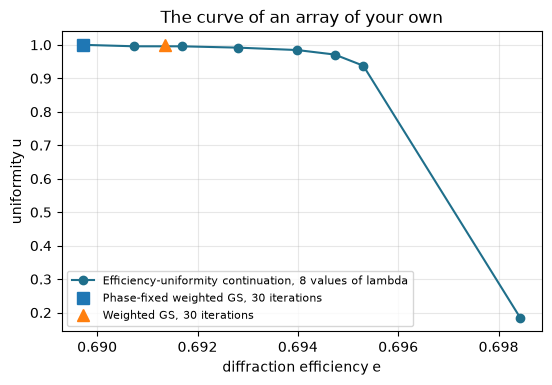

In [19]:
# the curve of the array of your own, with the two single-point holograms
fig, ax = plt.subplots(figsize=(6.2, 3.9))
ax.plot(mine_front[:, 0], mine_front[:, 1], "o-", color="#1f6f8b",
    label="Efficiency-uniformity continuation, 8 values of lambda")
for name, mark, label in (("Phase-fixed weighted GS", "s", "Phase-fixed weighted GS, 30 iterations"), ("Weighted GS",
    "^", "Weighted GS, 30 iterations")):
    h = singles[name].history[-1]
    ax.plot(h["efficiency"], h["uniformity"], mark, markersize=8, label=label)
ax.set_xlabel("diffraction efficiency e")
ax.set_ylabel("uniformity u")
ax.set_title("The curve of an array of your own")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()

For this array the curve runs from an efficiency of 0.6897 and a uniformity of 1.0000 at $\lambda = 0$ to 0.6984 and 0.1843 at $\lambda = 1$, a gain of 1.3 percent of the light that costs most of the uniformity. The phase-fixed weighted GS start sits at 0.6897 and 1.0000, and 1 of the curve points are at least as good as it on both axes to within 0.001, which for the start of the continuation is its own end of the curve; weighted GS sits at 0.6914 and 0.9989, with 0 curve points at least as good. These counts are the reading to act on: a single point with no curve point at least as good as it is on the curve, one with several is below it. They do not say that the eight points are the whole curve; the previous section showed that the density of $\lambda$, the budget and the start all move it. What to check in your own run is the first line of the printout, the uniform end of the curve, which must be equal to the efficiency of the start, and the monotone fall of the uniformity along $\lambda$; a curve that is not monotone means the continuation lost its way and the budget per value is too short. The figure is for one array and one random draw of positions, and it does not support a statement about arrays of another density.

## Results

**Answer:** On the 10 x 10 task the continuation traces a curve of 20 points, non-dominated among themselves, that runs from an efficiency of 0.7930 and a uniformity of 1.0000 to an efficiency of 0.8334 and a uniformity of 0.0074: it gains 5.1 percent of the light and loses all the uniformity, so the trade-off is steep and almost entirely paid in uniformity. On seed 1 five of the six single-point methods lie below it, each dominated by between 1 and 9 curve points (four and six on seeds 2 and 3); phase-fixed weighted GS lies on it, since the curve starts from phase-fixed weighted GS's own hologram (0.7931 against 0.7930 at its uniformity). The hypervolume of the curve, 0.8198, exceeds that of the six points, 0.8074, and that of the four of the criterion, 0.8028. The claim does not survive a stronger baseline unchanged: weighted GS with 100 iterations, at 0.8075 and 0.9887, dominates 4 of the 20 curve points. Started from that hologram, the continuation gives a curve whose uniform end is at 0.8075 and 1.0000, with a hypervolume of 0.8216; the two curves interleave and their union reaches 0.8220. The area the curve adds over the five published points depends on the reference of the hypervolume: +0.0124 from the origin and +0.0008 at the uniformity floor (0, 0.9), because the gain of the curve lies on the efficient side, where the uniformity is far below one.

What the notebook does not establish is the Pareto front of the task: the curve is below it wherever a published iterate dominates one of its points, and the product's benchmark, which stores one curve per geometry, gives it no win under its rule of five seeds on each side (this notebook does not rerun the benchmark). The dominance count was repeated on three seeds and gave five, four and six of the six single points below the curve, so the count belongs to the seed, while the hypervolume criterion held on all three; the efficiency range of the curve is small enough that a different beam or trap count could change its shape.

## Summary

- A hologram is a point in the plane of efficiency and uniformity, and a method with a free parameter is a curve; the Pareto front is the set that nothing dominates, and the curve of a method is a front only if no point reachable by another method dominates it.
- The efficiency-uniformity continuation traces it by continuation on one loss, with $\lambda$ moving from equal traps to light only, warm-started along the way.
- On this task the curve is steep: 5.1 percent more light costs all the uniformity.
- At the benchmark's budget five of six single-point methods lie below the curve on seed 1 (four and six on seeds 2 and 3), with margins from about 0.003 to 0.1348 of the light at equal uniformity; phase-fixed weighted GS, its start, lies on it.
- The area the curve adds over the five published points is +0.0124 from the origin and only +0.0008 at the uniformity floor (0, 0.9): the gain lies where the uniformity is far below one.
- The curve depends on its start, its budget and its number of $\lambda$: weighted GS at 100 iterations dominates 4 of its 20 points, and a curve started from that hologram is higher at both ends but interleaves with the first.

## References

- Di Leonardo, Ianni and Ruocco (2007). Computer generation of optimal holograms for optical trap arrays. Optics Express 15, 1913. https://doi.org/10.1364/OE.15.001913
- Polin et al. (2005). Optimized holographic optical traps. Optics Express 13, 5831. https://doi.org/10.1364/OPEX.13.005831
- Kim et al. (2019). Large-scale uniform optical focus array generation with a phase spatial light modulator. Optics Letters 44, 3178. https://doi.org/10.1364/OL.44.003178
- Boyd and Vandenberghe (2004). Convex Optimization, chapter 4.7 on multicriterion optimization and Pareto optimality. Cambridge University Press. https://web.stanford.edu/~boyd/cvxbook/
